Q1)

In [4]:
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *

#Load dataset
dataset = load_dataset("scikit-learn/churn-prediction")
df = dataset['train'].to_pandas()

#selection predictors nd target
x = df[["tenure","MonthlyCharges"]]
y = df["Churn"].map({"No":0,"Yes":1})

# Train-test split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

#Fit Logistic Regression
model = LogisticRegression()
model.fit(x_train,y_train)

#Predict
y_pred = model.predict(x_test)

#confusion matrix
print("Confusion Matrix: ")
print(confusion_matrix(y_test,y_pred))

#performance metric
print("\n Performance Metrics")
print("---------------------")
print("Accuracy: ",accuracy_score(y_test,y_pred))
print("Precision: ",precision_score(y_test,y_pred))
print("Recall: ",recall_score(y_test,y_pred))
print("F1-score: ",f1_score(y_test,y_pred))

#Complete classification report
print("\n Classification Report")
print("-----------------------")
print(classification_report(y_test,y_pred))

Confusion Matrix: 
[[931 104]
 [215 159]]

 Performance Metrics
---------------------
Accuracy:  0.7735982966643009
Precision:  0.6045627376425855
Recall:  0.42513368983957217
F1-score:  0.49921507064364207

 Classification Report
-----------------------
              precision    recall  f1-score   support

           0       0.81      0.90      0.85      1035
           1       0.60      0.43      0.50       374

    accuracy                           0.77      1409
   macro avg       0.71      0.66      0.68      1409
weighted avg       0.76      0.77      0.76      1409



The missed classified value is 319 (right to left diagonal value in confusion metric)

0.8100855098297552


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

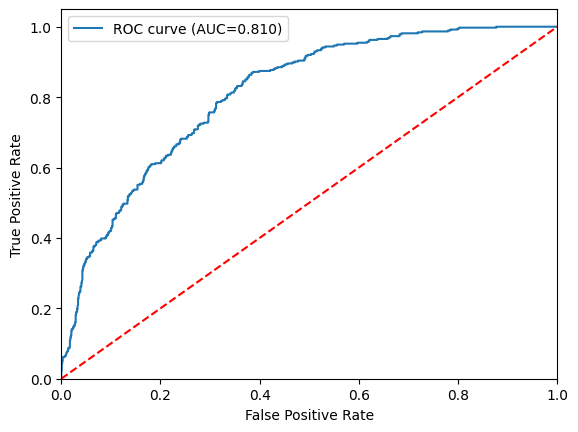

In [7]:
from sklearn.metrics import *
import matplotlib.pyplot as plt

#predicted probabilities for churn
y_pred_prob = model.predict_proba(x_test)[:,1]

#roc curve
fpr,tpr,threshold = roc_curve(y_test,y_pred_prob)

#AUC
auc = roc_auc_score(y_test,y_pred_prob)
print(auc)

#plot roc curve
plt.plot(fpr,tpr,label=f"ROC curve (AUC={auc:.3f})")
plt.legend()
plt.plot([0,1],[0,1],'r--')
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt

Q2)

In [12]:
from sklearn import feature_extraction
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *
import seaborn as sns

# Load dataset
df = sns.load_dataset("penguins")

# Filter for Adelie and Gentoo species, select features, and drop NaNs
df1 = df[df['species'].isin(['Adelie', 'Gentoo'])].copy()
feature = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
df1 = df1[feature + ['species']].dropna()

# selection predictors and target using the cleaned df1
x = df1[feature]
y = (df1["species"] == "Gentoo").astype(int)

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

# Fit Logistic Regression
model1 = LogisticRegression(max_iter=1000)
model1.fit(x_train, y_train)

# Predict
y_pred = model1.predict(x_test)

# confusion matrix
print("Confusion Matrix: ")
print(confusion_matrix(y_test, y_pred))

# performance metric
print("\n Performance Metrics")
print("---------------------")
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))
print("F1-score: ", f1_score(y_test, y_pred))

# Complete classification report
print("\n Classification Report")
print("-----------------------")
print(classification_report(y_test, y_pred))

Confusion Matrix: 
[[30  0]
 [ 0 25]]

 Performance Metrics
---------------------
Accuracy:  1.0
Precision:  1.0
Recall:  1.0
F1-score:  1.0

 Classification Report
-----------------------
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        25

    accuracy                           1.00        55
   macro avg       1.00      1.00      1.00        55
weighted avg       1.00      1.00      1.00        55



1.0


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

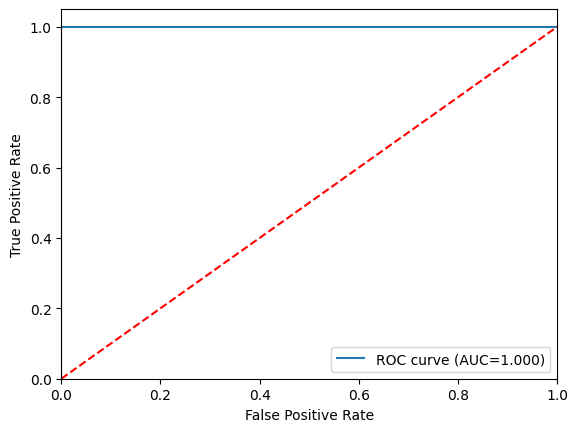

In [15]:
from sklearn.metrics import *
import matplotlib.pyplot as plt

#predicted probabilities for churn
y_pred_prob = model1.predict_proba(x_test)[:,1]

#roc curve
fpr,tpr,threshold = roc_curve(y_test,y_pred_prob)

#AUC
auc = roc_auc_score(y_test,y_pred_prob)
print(auc)

#plot roc curve
plt.plot(fpr,tpr,label=f"ROC curve (AUC={auc:.3f})")
plt.legend()
plt.plot([0,1],[0,1],'r--')
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt

Q3)

In [14]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

#4. standardize and fir logistic regression
model2 = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=1000))])
model2.fit(x_train,y_train)

#5. predict
y_pred = model2.predict(x_test)
y_pred_prob = model2.predict_proba(x_test)[:,1]

#6. Evaluation Metrics
print("Confusion Matrix: ")
print(confusion_matrix(y_test,y_pred))

print("\n Performance Metrics")
print("---------------------")
print("Accuracy: ",accuracy_score(y_test,y_pred))
print("Precision: ",precision_score(y_test,y_pred))
print("Recall: ",recall_score(y_test,y_pred))
print("F1-score: ",f1_score(y_test,y_pred))

Confusion Matrix: 
[[30  0]
 [ 0 25]]

 Performance Metrics
---------------------
Accuracy:  1.0
Precision:  1.0
Recall:  1.0
F1-score:  1.0


1.0


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

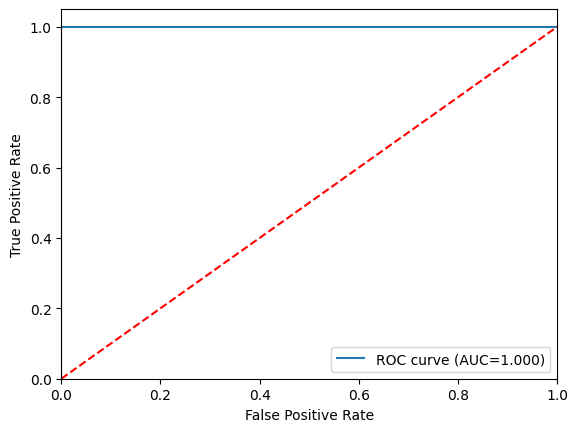

In [18]:
from sklearn.metrics import *
import matplotlib.pyplot as plt

#predicted probabilities for churn
y_pred_prob = model2.predict_proba(x_test)[:,1]

#roc curve
fpr,tpr,threshold = roc_curve(y_test,y_pred_prob)

#AUC
auc = roc_auc_score(y_test,y_pred_prob)
print(auc)

#plot roc curve
plt.plot(fpr,tpr,label=f"ROC curve (AUC={auc:.3f})")
plt.legend()
plt.plot([0,1],[0,1],'r--')
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt